# 01 — Exploratory Data Analysis (Phase 1)

**Goal:** understand the two public sources before the semi-synthetic dataset is built.

1. Supersociedades, *10,000 largest companies*: income and expense distribution by sector, and the quantization problem.
2. DIAN, *monthly tax collection*: the yearly seasonality curve and the bimonthly VAT pattern.

Raw files are expected in `ml/data/raw/` (not committed; download links in `ml/README.md`):
`supersociedades_10000_companies.csv` and `dian_monthly_collection_2000_2026.xlsx`.

> These are real public aggregates. The monthly series used to train the model are **semi-synthetic** (see `docs/01_business_and_data.md`, section 7).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repository root: the first parent folder that contains "ml".
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir())
RAW = ROOT / "ml" / "data" / "raw"

SECTORS = {"AGROPECUARIO": "agriculture", "COMERCIO": "retail", "CONSTRUCCION": "construction",
           "MANUFACTURA": "manufacturing", "MINERO": "mining", "SERVICIOS": "services"}

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## 1. Supersociedades: overview

In [2]:
raw = pd.read_csv(RAW / "supersociedades_10000_companies.csv", dtype=str, encoding_errors="replace")

def amount(s):
    # '$ 0.03', '$0.03' or '-$ 0.82' -> float, in trillions of COP (Spanish "billones")
    return pd.to_numeric(s.str.replace("[$, ]", "", regex=True), errors="coerce")

def sector(name):
    key = name.upper().strip()
    return SECTORS["CONSTRUCCION"] if key.startswith("CONSTRUCC") else SECTORS.get(key)

df = pd.DataFrame({
    "nit": raw["nit"],
    "year": pd.to_numeric(raw["a_o_de_corte"]).astype(int),
    "sector": raw["macrosector"].map(sector),
    "income": amount(raw["ingresos_operacionales"]),
    "profit": amount(raw["ganancia_p_rdida"]),
})
df["expenses"] = df["income"] - df["profit"]  # not reported directly

print(f"{len(df):,} rows, {df['nit'].nunique():,} distinct NITs, years {df['year'].min()}-{df['year'].max()}")
df.pivot_table(index="sector", columns="year", values="nit", aggfunc="count")

50,000 rows, 15,032 distinct NITs, years 2021-2025


year,2021,2022,2023,2024,2025
sector,,,,,
agriculture,462,465,403,393,419
construction,814,772,767,756,745
manufacturing,2040,2095,1962,1920,2016
mining,196,208,184,182,177
retail,3382,3374,3444,3417,3718
services,3106,3086,3240,3332,2925


Each cutoff year has exactly 10,000 companies. Retail and services dominate; mining and agriculture are small.
Many NITs appear in several years, which allows measuring real year-over-year growth.

## 2. Quantization: amounts are rounded to 0.01 trillion COP

In [3]:
print("Most frequent income values (trillions COP):")
print(df["income"].value_counts().head(6).to_string())
print()
print("Most frequent profit values (trillions COP):")
print(df["profit"].value_counts().head(4).to_string())
print()
print(f"Income below 0.05 trillion (quantized): {(df['income'] < 0.05).mean():.1%} of rows")
print(f"Income >= 0.5 trillion (precise margin): {(df['income'] >= 0.5).sum():,} rows")

Most frequent income values (trillions COP):
income
0.02    9337
0.03    8724
0.04    5571
0.05    3883
0.06    2954
0.07    2162

Most frequent profit values (trillions COP):
profit
 0.00    35167
 0.01     7264
 0.02     1977
-0.01     1142

Income below 0.05 trillion (quantized): 49.9% of rows
Income >= 0.5 trillion (precise margin): 2,679 rows


Half of the rows have income below 0.05 trillion (only 5 possible values), and about 70 % of profits are exactly `0.00`.
A margin computed from those rows is meaningless. **Treatment (Phase 2):** margins and growth are computed only from records with income ≥ 0.5 trillion COP, where rounding moves the margin by at most 1 percentage point.

## 3. Income and expense distribution by sector (2025)

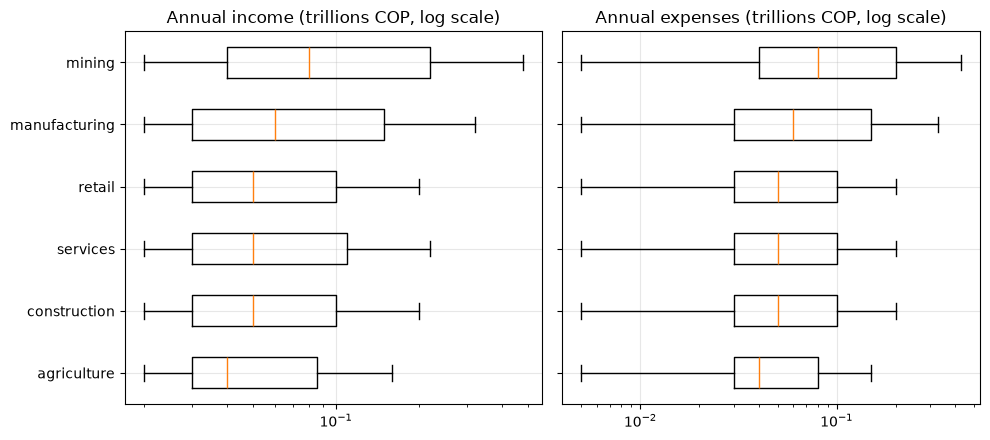

,income,expenses
sector,,
agriculture,0.04,0.04
construction,0.05,0.05
services,0.05,0.05
retail,0.05,0.05
manufacturing,0.06,0.06
mining,0.08,0.08


In [4]:
latest = df[df["year"] == df["year"].max()]
order = latest.groupby("sector")["income"].median().sort_values().index

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, col in zip(axes, ["income", "expenses"]):
    data = [latest.loc[latest["sector"] == s, col].clip(lower=0.005) for s in order]
    ax.boxplot(data, orientation="horizontal", showfliers=False)
    ax.set_xscale("log")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"Annual {col} (trillions COP, log scale)")
axes[0].set_yticks(range(1, len(order) + 1), order)
plt.tight_layout()
plt.show()

latest.groupby("sector")[["income", "expenses"]].median().loc[order].round(3)

Distributions are very skewed (log scale): a few huge companies and many near the 0.01–0.05 trillion floor.
Expenses follow income closely because margins are thin. These absolute sizes are **not** small-business sizes, which is why Phase 2 keeps only relative quantities and rescales every company.

## 4. Net margin by sector (precise records only)

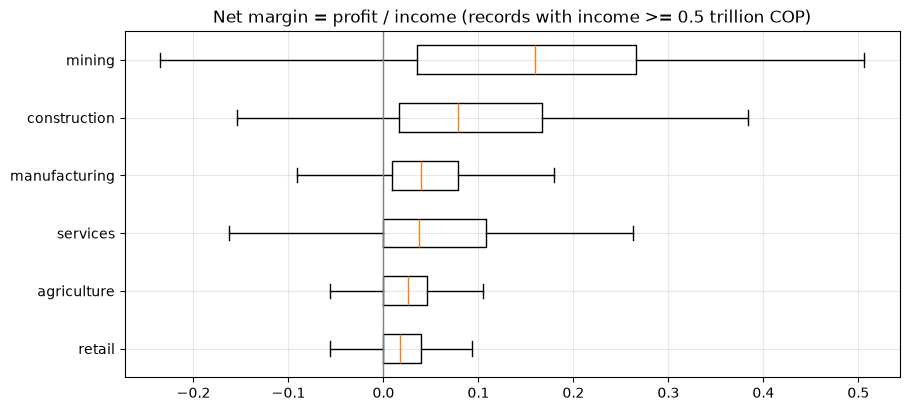

,count,median
sector,,
retail,805,0.018
agriculture,55,0.026
services,613,0.038
manufacturing,837,0.039
construction,125,0.078
mining,151,0.160


In [5]:
precise = df[(df["income"] >= 0.5)].assign(margin=lambda d: d["profit"] / d["income"])
precise = precise[precise["margin"].between(-0.5, 0.6)]

order_m = precise.groupby("sector")["margin"].median().sort_values().index
plt.boxplot([precise.loc[precise["sector"] == s, "margin"] for s in order_m], orientation="horizontal", showfliers=False)
plt.yticks(range(1, len(order_m) + 1), order_m)
plt.axvline(0, color="grey", lw=1)
plt.title("Net margin = profit / income (records with income >= 0.5 trillion COP)")
plt.show()

precise.groupby("sector")["margin"].agg(["count", "median"]).loc[order_m].round(3)

Retail works with the thinnest margins (median ≈ 1.8 %) and mining with the widest (≈ 16 %).
Thin margins mean that a small forecast error can turn a projected profit into a projected loss: this supports the 15 % business criterion and the "projected loss month" alert.

## 5. DIAN: monthly VAT collection and the bimonthly pattern

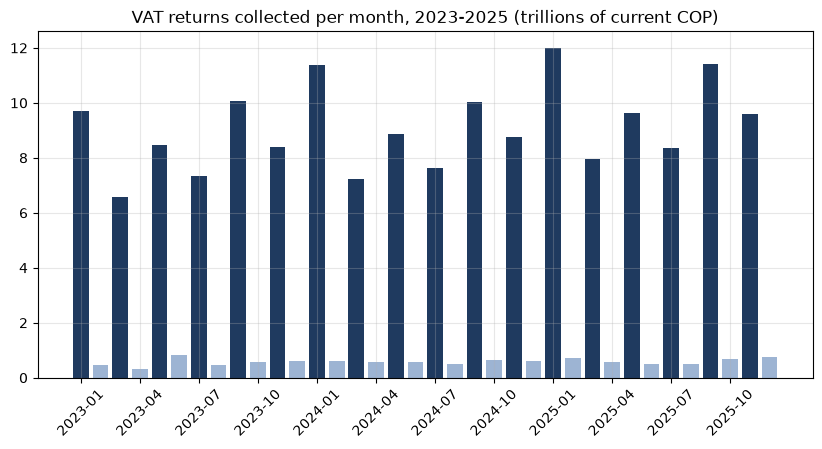

In [6]:
xl = pd.read_excel(RAW / "dian_monthly_collection_2000_2026.xlsx", header=8)
months_es = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
             "septiembre", "octubre", "noviembre", "diciembre"]
vat_col = next(c for c in xl.columns if str(c).startswith("2.1. Declaraciones IVA"))

dian = pd.DataFrame({
    "year": pd.to_numeric(xl.iloc[:, 0], errors="coerce"),
    "month": xl.iloc[:, 1].astype(str).str.strip().str.lower().map({m: i + 1 for i, m in enumerate(months_es)}),
    "vat": pd.to_numeric(xl[vat_col], errors="coerce"),
}).dropna().astype({"year": int, "month": int})

recent = dian[dian["year"].between(2023, 2025)]
plt.bar(range(len(recent)), recent["vat"] / 1e6, color=np.where(recent["month"] % 2 == 1, "#1F3A5F", "#9DB4D3"))
plt.xticks(range(0, len(recent), 3), [f"{y}-{m:02d}" for y, m in zip(recent["year"], recent["month"])][::3], rotation=45)
plt.title("VAT returns collected per month, 2023-2025 (trillions of current COP)")
plt.show()

VAT is filed every two months, in the month after each period, so collection is high in odd months (dark bars) and almost zero in even months.
This is a **filing calendar**, not a business pattern: it must be removed before using DIAN as a seasonality reference.

## 6. Seasonality curve

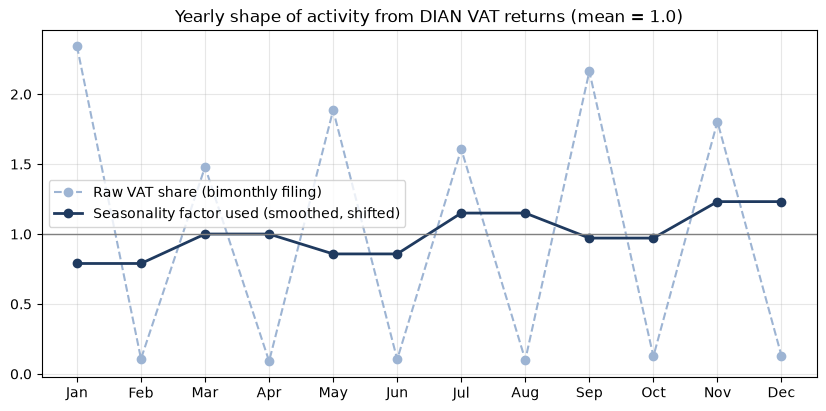

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
factor,0.789,0.789,1.0,1.0,0.858,0.858,1.15,1.15,0.971,0.971,1.232,1.232


In [7]:
years = [2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]  # complete years, without COVID
d = dian[dian["year"].isin(years)].copy()
d["share"] = d["vat"] / d.groupby("year")["vat"].transform("sum") * 12
raw_shape = d.groupby("month")["share"].median().to_numpy()

paired = raw_shape.copy()
for first in (1, 3, 5, 7, 9, 11):           # average each filing pair (Jan-Feb, Mar-Apr, ...)
    paired[first - 1] = paired[first] = raw_shape[first - 1 : first + 1].mean()
activity = np.roll(paired, -2)               # collection in Mar-Apr reflects sales of Jan-Feb
activity /= activity.mean()

labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.plot(labels, raw_shape, "o--", color="#9DB4D3", label="Raw VAT share (bimonthly filing)")
plt.plot(labels, activity, "o-", color="#1F3A5F", lw=2, label="Seasonality factor used (smoothed, shifted)")
plt.axhline(1, color="grey", lw=1)
plt.title("Yearly shape of activity from DIAN VAT returns (mean = 1.0)")
plt.legend()
plt.show()

pd.Series(activity.round(3), index=labels, name="factor").to_frame().T

After smoothing and shifting, activity is lowest in January–February (≈ 0.79) and highest in November–December (≈ 1.23), consistent with the Colombian retail calendar.
These 12 factors are the only thing taken from DIAN; its amounts are national totals and are never used as any company's figures.

## 7. Conclusions for the project

| Finding | Consequence |
|---|---|
| Supersociedades amounts are rounded to 0.01 trillion COP; half the rows are quantized | Margins and growth only from records with income ≥ 0.5 trillion |
| Real margins are thin (retail ≈ 1.8 %) | Small forecast errors matter; supports the 15 % business criterion |
| The source covers only the largest companies | Keep relative quantities and rescale to small-business size |
| DIAN VAT shows a bimonthly filing pattern | Smooth by filing pairs and shift 2 months before using it |
| DIAN is national | Use it only for the shape of seasonality |
| No source has monthly figures per company | The monthly dataset must be semi-synthetic, and this is stated everywhere |